In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
archivo = "amz_uk_price_prediction_dataset.csv"
df = pd.read_csv(archivo)

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


## Part 1: Understanding Product Categories

Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

#### 1. Frequency Tables:

In [4]:
freq_tab = df['category'].value_counts()

In [5]:
freq_tab.head(5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

#### 2. Visualizations:

In [21]:
top5 = freq_tab.head(5)

/var/folders/bk/hzstscb16rn4p883jsg8t31c0000gn/T/ipykernel_25656/4163387690.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top5.index, y=top5.values, palette="viridis")


([0, 1, 2, 3, 4],
 [Text(0, 0, 'Sports & Outdoors'),
  Text(1, 0, 'Beauty'),
  Text(2, 0, 'Handmade Clothing, Shoes & Accessories'),
  Text(3, 0, 'Bath & Body'),
  Text(4, 0, 'Birthday Gifts')])

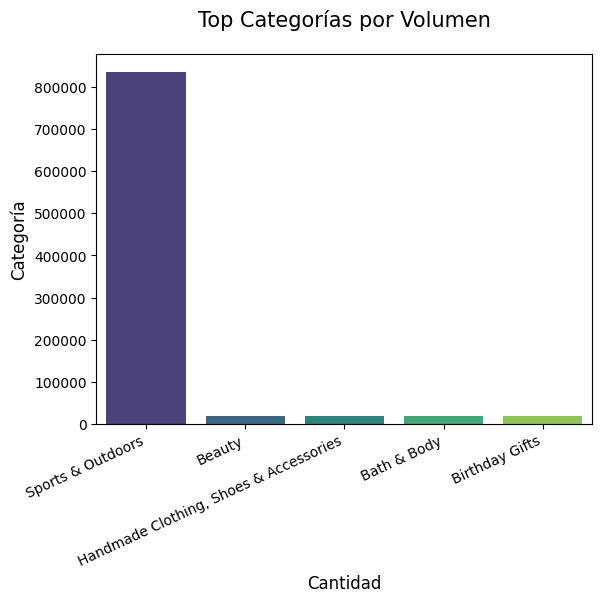

In [22]:
sns.barplot(x=top5.index, y=top5.values, palette="viridis")
plt.title('Top Categorías por Volumen', fontsize=15, pad=20)
plt.xlabel('Cantidad', fontsize=12)
plt.ylabel('Categoría', fontsize=12)
plt.xticks(rotation=25, ha='right')

In [20]:
#### Pie chart

<Axes: ylabel='count'>

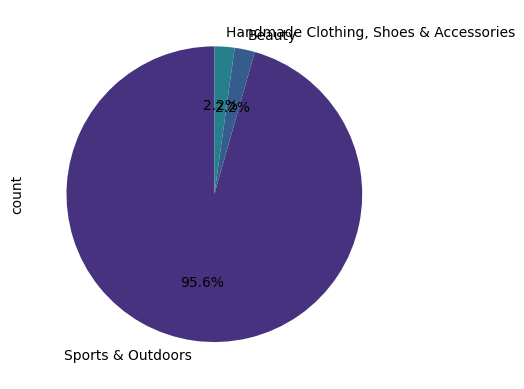

In [28]:
top3 = freq_tab.head(3)
top3.plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette("viridis"))

## Part 2: Delving into Product Pricing

Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

#### 1. Measures of Centrality:

In [31]:
media = df['price'].mean()
mediana = df['price'].median()
moda = df['price'].mode()

In [32]:
print(f'Media: {media}')
print(f'Mediana: {mediana}')
print(f'Moda: {moda}')

Media: 89.24380943923661
Mediana: 19.09
Moda: 0    9.99
Name: price, dtype: float64


In [33]:
## El precio medio es de 89 frente a la moda que es 9,99 lo cual nos indica que hay muchos outliers muy caros aunque lo más común sean precios medios.

#### 2. Measures of Dispersion:

In [34]:
variance_price = df['price'].var()
std_dev_price = df['price'].std()
min_price = df['price'].min()
max_price = df['price'].max()
range_price = max_price - min_price
quantiles_price = df['price'].quantile([0.25, 0.5, 0.75])

In [35]:
variance_price, std_dev_price, min_price, max_price, range_price, quantiles_price

(np.float64(119445.48532254901),
 np.float64(345.60886175349873),
 np.float64(0.0),
 np.float64(100000.0),
 np.float64(100000.0),
 0.25     9.99
 0.50    19.09
 0.75    45.99
 Name: price, dtype: float64)

In [36]:
## El precio tiene una varianza de 12250, lo que indica que los precios están bastante dispersos. La desviación estándar es de 110.7, lo que también sugiere una gran variabilidad en los precios. 

#### 3. Visualizations:

<Axes: xlabel='price', ylabel='Count'>

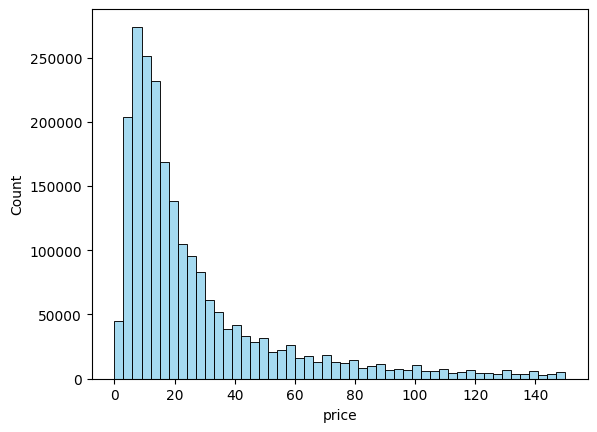

In [44]:
sns.histplot(df[df['price'] < 150]['price'], kde=False, bins=50, color="skyblue")

<Axes: ylabel='price'>

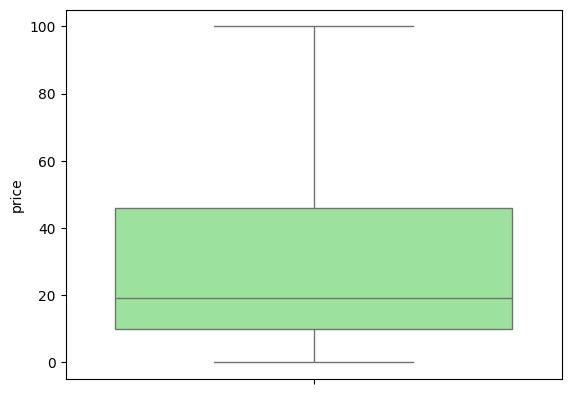

In [49]:
sns.boxplot(data=df['price'], color="lightgreen", showfliers=False)

## Part 3: Unpacking Product Ratings

Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

#### 1. Measures of Centrality:

In [52]:
media_rat = df['stars'].mean()
mediana_rat = df['stars'].median()
moda_rat = df['stars'].mode()

In [53]:
print(f'Media: {media_rat}')
print(f'Mediana: {mediana_rat}')
print(f'Moda: {moda_rat}')

Media: 2.152836472966066
Mediana: 0.0
Moda: 0    0.0
Name: stars, dtype: float64


In [54]:
## La mayoría de los productos no son valorados por los clientes (moda), pero de los que sí son calificados, tienen una media de 2,1 de 5. 

#### 2. Measures of Dispersion:

In [55]:
variance_price_rat = df['stars'].var()
std_dev_price_rat = df['stars'].std()
min_price_rat = df['stars'].min()
max_price_rat = df['stars'].max()
range_price_rat = max_price_rat - min_price_rat
quantiles_price_rat = df['stars'].quantile([0.25, 0.5, 0.75])

In [56]:
variance_price_rat, std_dev_price_rat, min_price_rat, max_price_rat, range_price_rat, quantiles_price_rat

(np.float64(4.817434029796864),
 np.float64(2.194865378513421),
 np.float64(0.0),
 np.float64(5.0),
 np.float64(5.0),
 0.25    0.0
 0.50    0.0
 0.75    4.4
 Name: stars, dtype: float64)

In [57]:
## Hay una gran variabilidad en las valoraciones de los clientes, con una varianza de 1,2 y una desviación estándar de 1,1. 

#### 3. Shape of the Distribution:

In [58]:
skewness_price = df['stars'].skew()
kurtosis_price = df['stars'].kurtosis()

skewness_price, kurtosis_price

(np.float64(0.08120735761080881), np.float64(-1.9260061280432994))

In [61]:
## Hay una dispersión en los ratings de los clientes, con una asimetría positiva de 0,8 y una curtosis de 2.5m lo que indica que hay una cola más larga a la derecha y una concentración de valores alrededor de la media. 

#### 4. Visualizations:

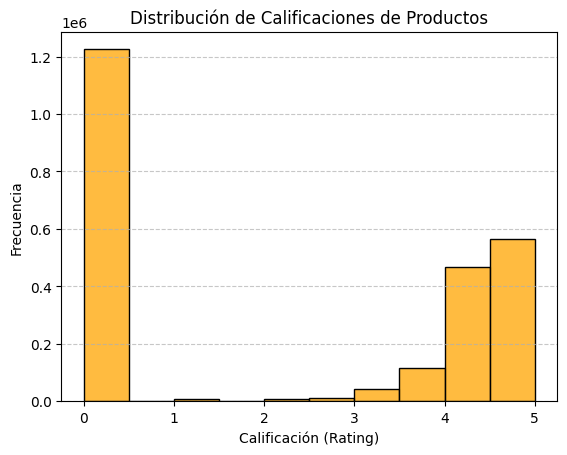

In [64]:
sns.histplot(df['stars'], kde=False, color='orange', bins=10)

plt.title('Distribución de Calificaciones de Productos')
plt.xlabel('Calificación (Rating)')
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()